<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI logo" width="180"></a>

# When similar images are different files

A perceptual hash is useful for finding candidates to review. It does not prove byte identity, preserve metadata, or tell us which file should be kept. We inspect three related image files, compare three 64-bit hash methods, and change one review threshold.

**These are unchanged synthetic repository fixtures**, not real photographs. The generator creates one RGB gradient, encodes PNG and JPEG siblings, then injects a deliberately invented EXIF GPS block into the JPEG. The coordinates are test data, not an observed place or a person’s location. Exact fixture paths, revision and SHA-256 hashes are bundled in `fixtures/provenance.json`.

## One candidate-review threshold

`MAX_PHASH_DISTANCE` accepts integers **0–64 bits**. A pair is selected when its pHash Hamming distance is **less than or equal** to the threshold. It applies only to pHash; the other methods are shown for comparison, without claiming equal calibration. Restart and run all after editing.

In [1]:
MAX_PHASH_DISTANCE = 8  # differing pHash bits; inclusive upper bound

In [2]:
import hashlib
import json
from io import BytesIO
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from PIL import Image

from notebook_support import finish, theme

assert type(MAX_PHASH_DISTANCE) is int and 0 <= MAX_PHASH_DISTANCE <= 64
manifest = json.loads(Path("fixtures/provenance.json").read_text())
for entry in manifest["files"]:
    assert hashlib.sha256((Path("fixtures") / entry["file"]).read_bytes()).hexdigest() == entry["sha256"]
connection = haybarn.connect()
theme()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%sql connection

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-image/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-image/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-image/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-image/notebooks/pyproject.toml.

## Read bytes, then ask the real image worker

The literal native release is downloaded and verified by VGI. SQL reads the notebook’s local fixture files. Image metadata and all perceptual hashes come from the worker and are materialized once; subsequent charts query the resulting tables.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'img' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-image@v0.4.0');
CREATE TABLE raw AS
SELECT regexp_extract(filename, '[^/]+$') AS name, content
FROM read_blob(['fixtures/gradient.png', 'fixtures/gradient.jpg', 'fixtures/gps.jpg']);
CREATE TABLE facts AS
SELECT name, content, octet_length(content) AS file_bytes, sha256(content) AS byte_sha256,
       img.main.image_info(content) AS info, img.main.exif_gps(content) AS gps,
       img.main.phash(content) AS phash, img.main.dhash(content) AS dhash, img.main.ahash(content) AS ahash
FROM raw;

,Count


In [4]:
%%sql inventory <<
SELECT name, file_bytes, info.format AS format, info.width AS width, info.height AS height,
       info.color AS color_model, info.has_alpha AS has_alpha, gps IS NOT NULL AS has_gps,
       byte_sha256
FROM facts ORDER BY name;

In [5]:
display(inventory)
display(
    Markdown(
        f"The worker decoded **{len(inventory)} files**. "
        f"Distinct byte SHA-256 values: **{inventory.byte_sha256.nunique()}**; "
        f"files with GPS fields: **{int(inventory.has_gps.sum())}**. "
        "Missing GPS is kept separate from a numeric coordinate of zero. "
        "Dimensions and approximate visual appearance alone do not reveal the metadata difference."
    )
)

,name,file_bytes,format,width,height,color_model,has_alpha,has_gps,byte_sha256
0,gps.jpg,4750,jpeg,160,120,rgb8,False,True,1690d5027eb5c14515a3edc60930e61446a7af69390dd7...
1,gradient.jpg,4612,jpeg,160,120,rgb8,False,False,20e6709b6e749085fc901ac68f23e0245c902634c16c42...
2,gradient.png,19082,png,160,120,rgb8,False,False,f39d7f3013c4de01a063e217b6377559c3a9db5ac42db5...


The worker decoded **3 files**. Distinct byte SHA-256 values: **3**; files with GPS fields: **1**. Missing GPS is kept separate from a numeric coordinate of zero. Dimensions and approximate visual appearance alone do not reveal the metadata difference.

In [6]:
%%sql previews <<
SELECT name, content, file_bytes, gps IS NOT NULL AS has_gps FROM facts ORDER BY name;

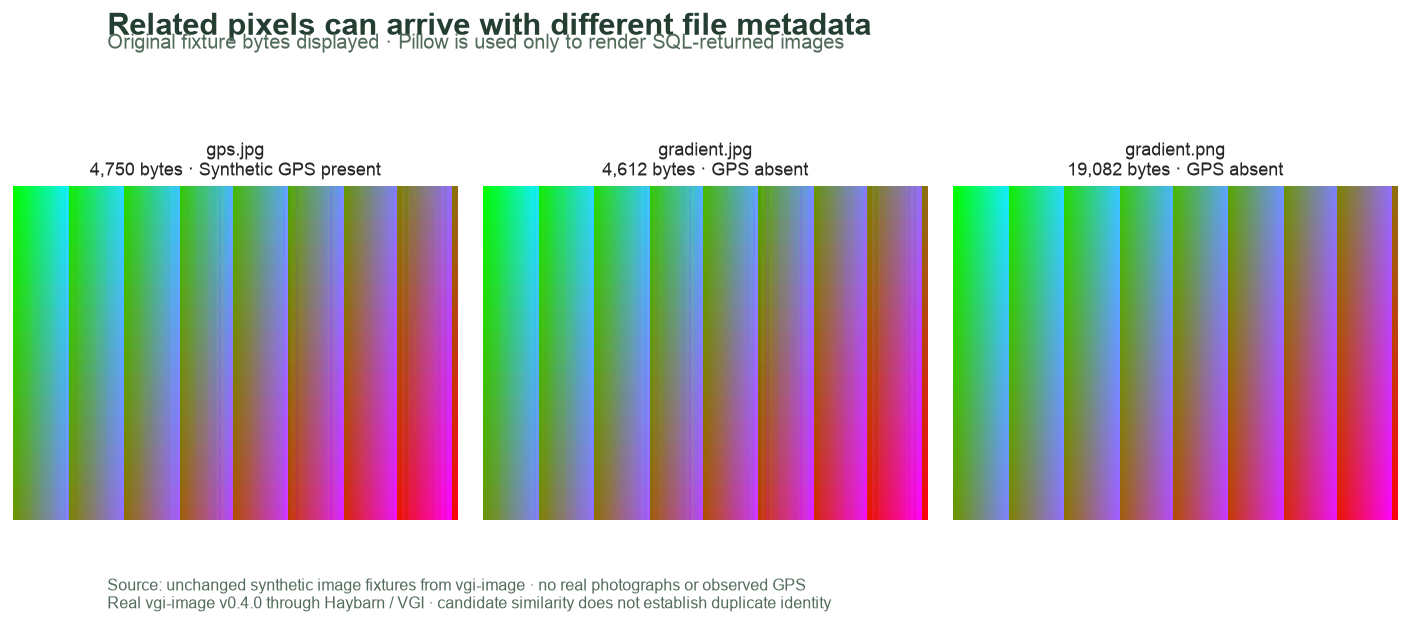

In [7]:
fig, axes = plt.subplots(1, len(previews), figsize=(11.5, 4.8), squeeze=False)
for ax, row in zip(axes[0], previews.itertuples(), strict=True):
    ax.imshow(Image.open(BytesIO(bytes(row.content))), interpolation="nearest")
    ax.axis("off")
    gps_label = "Synthetic GPS present" if row.has_gps else "GPS absent"
    ax.set_title(f"{row.name}\n{row.file_bytes:,} bytes · {gps_label}", fontsize=10)
finish(
    fig,
    "source-files",
    "Related pixels can arrive with different file metadata",
    "Original fixture bytes displayed · Pillow is used only to render SQL-returned images",
)

## Compare unique pairs with three hash methods

Each fingerprint is a 64-bit unsigned integer. `phash_distance` counts differing bits and can compare any of these same-width fingerprints; it does not turn the three algorithms into equivalent measures. We form each unordered file pair once, then retain exact-byte identity and GPS-presence differences beside the distances.

In [8]:
%%sql
CREATE TABLE pairs AS
SELECT a.name AS left_file, b.name AS right_file,
       a.byte_sha256=b.byte_sha256 AS same_bytes,
       (a.gps IS NOT NULL)<>(b.gps IS NOT NULL) AS gps_presence_differs,
       img.main.phash_distance(a.phash,b.phash) AS phash_bits,
       img.main.phash_distance(a.dhash,b.dhash) AS dhash_bits,
       img.main.phash_distance(a.ahash,b.ahash) AS ahash_bits,
       img.main.phash_distance(b.phash,a.phash) AS reverse_phash_bits
FROM facts a JOIN facts b ON a.name<b.name;

,Count


In [9]:
%%sql distances <<
SELECT left_file, right_file, same_bytes, gps_presence_differs,
       phash_bits, dhash_bits, ahash_bits,
       phash_bits <= {{MAX_PHASH_DISTANCE}} AS review_candidate
FROM pairs ORDER BY left_file, right_file;

,left_file,right_file,same_bytes,gps_presence_differs,phash_bits,dhash_bits,ahash_bits,review_candidate
0,gps.jpg,gradient.jpg,False,True,0,0,0,True
1,gps.jpg,gradient.png,False,True,12,0,1,False
2,gradient.jpg,gradient.png,False,False,12,0,1,False


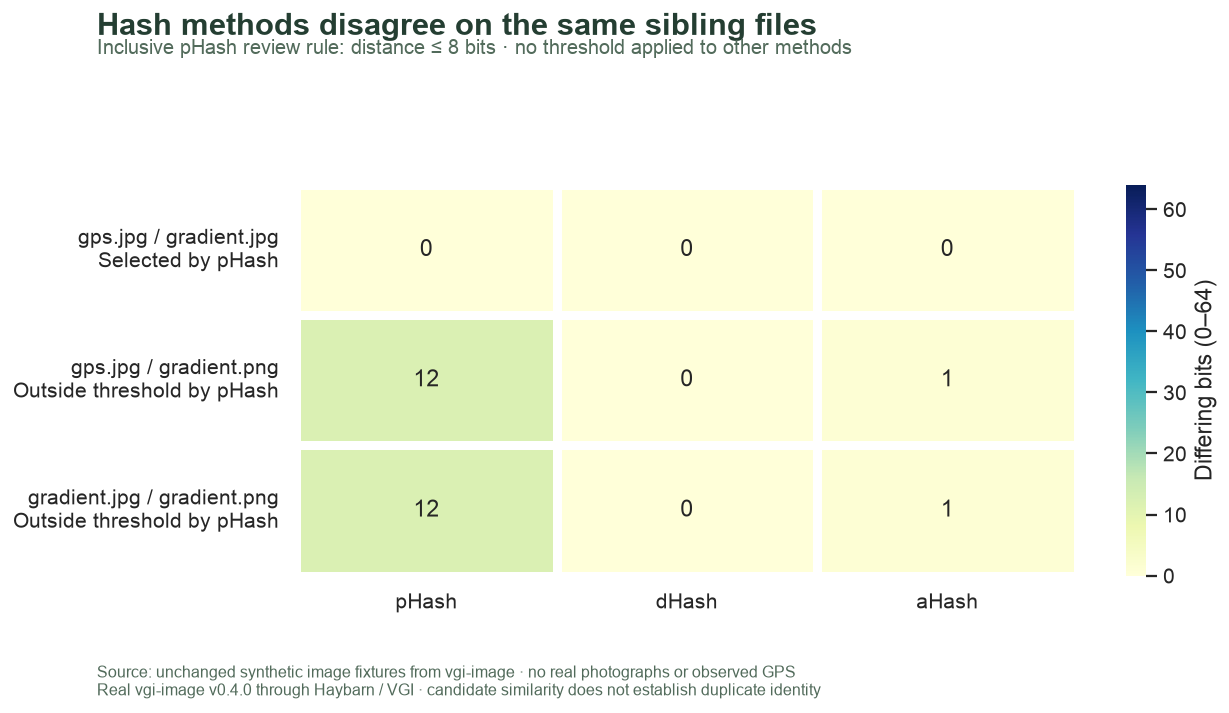

In [10]:
display(distances)
plot = distances.set_index(["left_file", "right_file"])[["phash_bits", "dhash_bits", "ahash_bits"]]
plot.columns = ["pHash", "dHash", "aHash"]
labels = [
    f"{r.left_file} / {r.right_file}\n{'Selected' if r.review_candidate else 'Outside threshold'} by pHash"
    for r in distances.itertuples()
]
fig, ax = plt.subplots(figsize=(10.5, 5.5))
sns.heatmap(
    plot,
    ax=ax,
    annot=True,
    fmt="d",
    vmin=0,
    vmax=64,
    cmap="YlGnBu",
    linewidths=4,
    linecolor="white",
    yticklabels=labels,
    cbar_kws={"label": "Differing bits (0–64)"},
)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)
finish(
    fig,
    f"distances-max-{MAX_PHASH_DISTANCE}",
    "Hash methods disagree on the same sibling files",
    f"Inclusive pHash review rule: distance ≤ {MAX_PHASH_DISTANCE} bits · no threshold applied to other methods",
)

In [11]:
candidates = distances[distances.review_candidate]
zero_but_different = int(((distances.phash_bits == 0) & ~distances.same_bytes).sum())
gps_differences = int(candidates.gps_presence_differs.sum())
display(
    Markdown(
        f"The **≤ {MAX_PHASH_DISTANCE}-bit** pHash rule selects **{len(candidates)} of {len(distances)} pairs**. "
        f"Selected pairs whose GPS presence differs: **{gps_differences}**. "
        f"Pairs with zero pHash distance but different byte hashes: **{zero_but_different}**. "
        "A candidate is an invitation to inspect both files and their metadata, not an instruction to delete one. "
        "The fixture generator establishes their relationship; the hash alone would not prove it."
    )
)

The **≤ 8-bit** pHash rule selects **1 of 3 pairs**. Selected pairs whose GPS presence differs: **1**. Pairs with zero pHash distance but different byte hashes: **1**. A candidate is an invitation to inspect both files and their metadata, not an instruction to delete one. The fixture generator establishes their relationship; the hash alone would not prove it.

## Check accounting and Hamming-distance invariants

These checks verify complete decoding, unsigned hash types, bounds, symmetry, self-distance and pair enumeration. They do not assert a universal similarity cutoff or treat absent metadata as corruption.

In [12]:
%%sql checks <<
SELECT 'file identities unique and bytes nonempty' AS check_name,
 count(*)>0 AND count(*)=count(DISTINCT name) AND bool_and(file_bytes>0) AS passed FROM facts
UNION ALL SELECT 'decoded dimensions present and positive',bool_and(info.width>0 AND info.height>0 AND info.format IS NOT NULL) FROM facts
UNION ALL SELECT 'hashes are complete unsigned64 values',bool_and(phash IS NOT NULL AND dhash IS NOT NULL AND ahash IS NOT NULL
 AND typeof(phash)='UBIGINT' AND typeof(dhash)='UBIGINT' AND typeof(ahash)='UBIGINT') FROM facts
UNION ALL SELECT 'all unordered pairs exactly once',count(*)=(SELECT count(*)*(count(*)-1)/2 FROM facts)
 AND count(*)=count(DISTINCT(left_file,right_file)) FROM pairs
UNION ALL SELECT 'all distances within64 bits',bool_and(phash_bits BETWEEN 0 AND 64 AND dhash_bits BETWEEN 0 AND 64 AND ahash_bits BETWEEN 0 AND 64) FROM pairs
UNION ALL SELECT 'pHash distance symmetric',bool_and(phash_bits=reverse_phash_bits) FROM pairs
UNION ALL SELECT 'pHash self-distance zero',bool_and(img.main.phash_distance(phash,phash)=0) FROM facts
UNION ALL SELECT 'GPS absence is not synthesized coordinates',count(*) FILTER(WHERE gps IS NOT NULL AND
 (gps.lat IS NULL OR gps.lon IS NULL OR gps.lat NOT BETWEEN -90 AND 90 OR gps.lon NOT BETWEEN -180 AND 180))=0 FROM facts;

In [13]:
display(checks)
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
display(
    Markdown(
        f"All **{len(checks)} invariants** pass. This is a deliberately related three-file fixture, "
        "so it cannot estimate false-positive rates, recall, or a threshold for a general photo library."
    )
)

,check_name,passed
0,file identities unique and bytes nonempty,True
1,decoded dimensions present and positive,True
2,hashes are complete unsigned64 values,True
3,all unordered pairs exactly once,True
4,all distances within64 bits,True
5,pHash distance symmetric,True
6,pHash self-distance zero,True
7,GPS absence is not synthesized coordinates,True


All **8 invariants** pass. This is a deliberately related three-file fixture, so it cannot estimate false-positive rates, recall, or a threshold for a general photo library.

## Try one change

Increase `MAX_PHASH_DISTANCE` from **8** to **16**, restart and run all. Predict which pair labels change in the distance chart and compare the candidate count. The images, bytes, metadata, fingerprints and distances must remain unchanged. A broader threshold can admit more pairs but does not make their bytes or metadata equal. Restore **8** for the saved default.

In [14]:
connection.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>